## Problem 12: Predicting the U.S. Equity Premium Using Economic and Financial Predictors

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_excel(
    "PredictorData2025.xlsx",
    sheet_name="Monthly",
    na_values="NaN"
)

df.head()

c:\Users\sirji\OneDrive\Desktop\Paper Replications\.venv\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,yyyymm,Index,D12,E12,b/m,tbl,AAA,BAA,lty,ntis,Rfree,infl,ltr,corpr,svar,csp,CRSP_SPvw,CRSP_SPvwx
0,187101,4.44,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,187102,4.50,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,187103,4.61,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,187104,4.74,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,187105,4.86,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004643,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.columns.tolist()

['yyyymm',
 'Index',
 'D12',
 'E12',
 'b/m',
 'tbl',
 'AAA',
 'BAA',
 'lty',
 'ntis',
 'Rfree',
 'infl',
 'ltr',
 'corpr',
 'svar',
 'csp',
 'CRSP_SPvw',
 'CRSP_SPvwx']

In [4]:
for column in df.columns:

    if column != "yyyymm":

        df[column] = pd.to_numeric(
            df[column]
            .astype(str)
            .str.replace(",", ""),
            errors="coerce"
        )

In [5]:
df["yyyymm"] = (
    df["yyyymm"]
    .astype(int)
    .astype(str)
)

df["DATE"] = pd.to_datetime(
    df["yyyymm"],
    format="%Y%m"
)

df = df.set_index("DATE")

df = df.sort_index()

df.head()

,yyyymm,Index,D12,E12,b/m,tbl,AAA,BAA,lty,ntis,Rfree,infl,ltr,corpr,svar,csp,CRSP_SPvw,CRSP_SPvwx
DATE,,,,,,,,,,,,,,,,,,
1871-01-01,187101,4.44,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1871-02-01,187102,4.50,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1871-03-01,187103,4.61,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1871-04-01,187104,4.74,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1871-05-01,187105,4.86,0.26,0.4,NaN,NaN,NaN,NaN,NaN,NaN,0.004643,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We will use observations from 1950 onward.

In [6]:
df = df.loc[
    "1950-01-01":"2025-12-01"
].copy()

df.shape

(912, 18)

**Construct the Equity Premium**

In [7]:
df["equity_premium"] = (
    100 *
    (
        df["CRSP_SPvw"]
        - df["Rfree"]
    )
)

In [8]:
df["future_equity_premium"] = (
    df["equity_premium"].shift(-1)
)

**Construct the Valuation Ratios**

In [9]:
# Dividend-price ratio
df["dp"] = (
    np.log(df["D12"])
    - np.log(df["Index"])
)

# Dividend yield
df["dy"] = (
    np.log(df["D12"])
    - np.log(df["Index"].shift(1))
)

# Earnings-price ratio
df["ep"] = (
    np.log(df["E12"])
    - np.log(df["Index"])
)

# Dividend-payout ratio
df["de"] = (
    np.log(df["D12"])
    - np.log(df["E12"])
)

df["bm"] = df["b/m"]

df["tms"] = (
    df["lty"]
    - df["tbl"]
)

# Default yield spread
df["dfy"] = (
    df["BAA"]
    - df["AAA"]
)

# Default return spread
df["dfr"] = (
    df["corpr"]
    - df["ltr"]
)

In [10]:
features = [
    "dp",
    "dy",
    "ep",
    "de",
    "svar",
    "bm",
    "ntis",
    "tbl",
    "lty",
    "ltr",
    "tms",
    "dfy",
    "dfr",
    "infl"
]

model_df = df[
    features
    + ["future_equity_premium"]
].copy()

model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

model_df = model_df.dropna()

model_df.head()

,dp,dy,ep,de,svar,bm,ntis,tbl,lty,ltr,tms,dfy,dfr,infl,future_equity_premium
DATE,,,,,,,,,,,,,,,
1950-02-01,-2.697651,-2.687730,-1.990240,-0.707411,0.000426,0.784998,0.025492,0.0112,0.0214,0.0021,0.0102,0.0066,-0.0014,0.000000,0.7185
1950-03-01,-2.693125,-2.689068,-1.987238,-0.705886,0.000624,0.825528,0.029291,0.0112,0.0215,0.0008,0.0103,0.0066,0.0014,0.004255,4.4987
1950-04-01,-2.728739,-2.684614,-2.007733,-0.721006,0.000714,0.796497,0.026398,0.0115,0.0214,0.0030,0.0099,0.0063,-0.0038,0.000000,4.5902
1950-05-01,-2.758839,-2.720300,-2.023192,-0.735647,0.000641,0.761346,0.028572,0.0116,0.0213,0.0033,0.0097,0.0064,-0.0041,0.004237,-5.5224
1950-06-01,-2.690678,-2.750471,-1.940835,-0.749843,0.005856,0.813447,0.030397,0.0115,0.0216,-0.0025,0.0101,0.0066,0.0048,0.004219,1.5981


In [11]:
model_df.shape

(910, 15)

In [12]:
model_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 910 entries, 1950-02-01 to 2025-11-01
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dp                     910 non-null    float64
 1   dy                     910 non-null    float64
 2   ep                     910 non-null    float64
 3   de                     910 non-null    float64
 4   svar                   910 non-null    float64
 5   bm                     910 non-null    float64
 6   ntis                   910 non-null    float64
 7   tbl                    910 non-null    float64
 8   lty                    910 non-null    float64
 9   ltr                    910 non-null    float64
 10  tms                    910 non-null    float64
 11  dfy                    910 non-null    float64
 12  dfr                    910 non-null    float64
 13  infl                   910 non-null    float64
 14  future_equity_premium  910 non-null    float64
dty

In [13]:
model_df.describe().round(4)

,dp,dy,ep,de,svar,bm,ntis,tbl,lty,ltr,tms,dfy,dfr,infl,future_equity_premium
count,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000,910.0000
mean,-3.5825,-3.5759,-2.8328,-0.7497,0.0021,0.4905,0.0109,0.0406,0.0562,0.0049,0.0156,0.0095,0.0003,0.0029,0.6881
std,0.4474,0.4474,0.4314,0.2875,0.0046,0.2503,0.0196,0.0303,0.0282,0.0272,0.0141,0.0042,0.0142,0.0036,4.2073
min,-4.5236,-4.5309,-4.8365,-1.2442,0.0001,0.1205,-0.0560,0.0001,0.0062,-0.1124,-0.0365,0.0032,-0.0976,-0.0192,-22.1795
25%,-3.9569,-3.9500,-3.1053,-0.9223,0.0006,0.2823,-0.0028,0.0164,0.0346,-0.0102,0.0056,0.0068,-0.0053,0.0000,-1.8111
50%,-3.5166,-3.5125,-2.8743,-0.7465,0.0011,0.4668,0.0145,0.0389,0.0488,0.0027,0.0144,0.0084,0.0007,0.0028,0.9866
75%,-3.2753,-3.2683,-2.5418,-0.5936,0.0021,0.6550,0.0259,0.0558,0.0753,0.0200,0.0264,0.0112,0.0059,0.0049,3.4278
max,-2.5979,-2.5857,-1.8987,1.3795,0.0732,1.2065,0.0512,0.1630,0.1482,0.1523,0.0455,0.0338,0.0737,0.0181,16.3013


**Plot: Equity Premium**

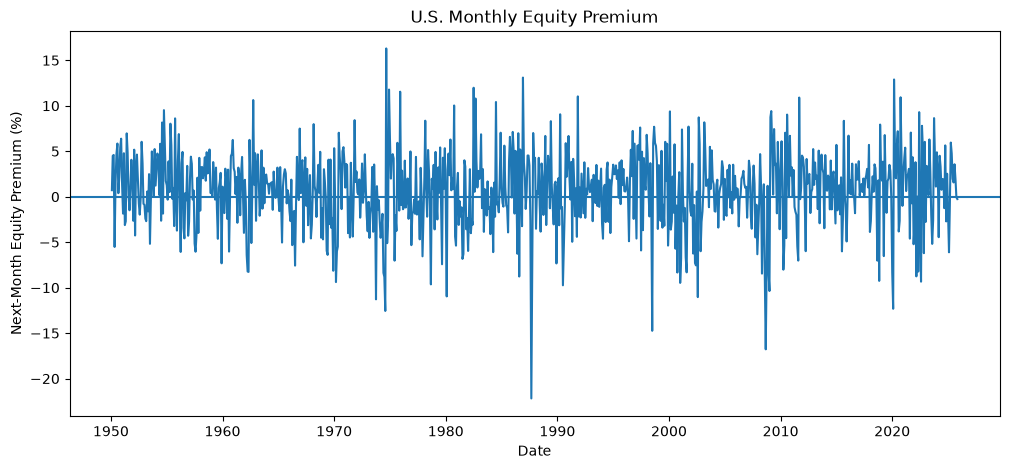

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    model_df.index,
    model_df["future_equity_premium"]
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Next-Month Equity Premium (%)"
)

plt.title(
    "U.S. Monthly Equity Premium"
)

plt.show()

In [15]:
correlations = (
    model_df
    .corr()["future_equity_premium"]
    .sort_values(ascending=False)
)

correlations.round(3)

future_equity_premium    1.000
ltr                      0.076
dy                       0.054
dp                       0.052
tms                      0.046
de                       0.033
ep                       0.032
dfr                      0.027
dfy                      0.024
bm                       0.020
svar                    -0.022
ntis                    -0.026
lty                     -0.068
infl                    -0.074
tbl                     -0.085
Name: future_equity_premium, dtype: float64

In [16]:
X = model_df[features]

y = model_df[
    "future_equity_premium"
]

In [17]:
print(X.shape)
print(y.shape)

(910, 14)
(910,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    shuffle=False
)

X_train = X_train.iloc[:-1]

y_train = y_train.iloc[:-1]

In [19]:
print(
    "Training observations:",
    len(X_train)
)

print(
    "Test observations:",
    len(X_test)
)

print()

print(
    "Training period:",
    X_train.index.min(),
    "to",
    X_train.index.max()
)

print()

print(
    "Test period:",
    X_test.index.min(),
    "to",
    X_test.index.max()
)

Training observations: 727
Test observations: 182

Training period: 1950-02-01 00:00:00 to 2010-08-01 00:00:00

Test period: 2010-10-01 00:00:00 to 2025-11-01 00:00:00


**Historical-Average Benchmark**

In [20]:
historical_mean = y_train.mean()

historical_mean_pred = np.repeat(
    historical_mean,
    len(y_test)
)

print(
    "Historical mean equity premium:",
    historical_mean
)

Historical mean equity premium: 0.5808579092159568


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

**OLS Benchmark**

In [22]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

ols_pred = ols.predict(
    X_test_scaled
)

In [23]:
ols_coefficients = pd.Series(
    ols.coef_,
    index=features,
    name="OLS"
)

ols_coefficients.round(4)

dp      1.8110
dy     -2.1541
ep      1.3253
de      0.5933
svar   -0.6707
bm     -0.3876
ntis   -0.1406
tbl    -0.3251
lty    -0.2248
ltr     0.6326
tms     0.2430
dfy     0.3451
dfr     0.3774
infl   -0.1615
Name: OLS, dtype: float64

In [24]:
alpha_values = np.logspace(
    -4,
    1,
    150
)

alpha_values[:10]

array([0.0001    , 0.00010803, 0.00011671, 0.00012609, 0.00013622,
       0.00014716, 0.00015898, 0.00017175, 0.00018555, 0.00020045])

**Time-Series Cross-Validation**

In [25]:
tscv = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

In [26]:
lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(
            max_iter=100000
        )
    )
])

**Tune Alpha**

In [27]:
parameter_grid = {
    "lasso__alpha": alpha_values
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=parameter_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+01])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

In [28]:
best_alpha = (
    lasso_search
    .best_params_["lasso__alpha"]
)

print(
    "Best alpha:",
    best_alpha
)

Best alpha: 0.7228703350949574


In [29]:
best_lasso = (
    lasso_search.best_estimator_
)

lasso_pred = best_lasso.predict(
    X_test
)

In [30]:
lasso_coefficients = pd.Series(
    best_lasso
    .named_steps["lasso"]
    .coef_,
    index=features,
    name="LASSO"
)

lasso_coefficients.round(4)

dp      0.0
dy      0.0
ep      0.0
de      0.0
svar    0.0
bm      0.0
ntis    0.0
tbl     0.0
lty     0.0
ltr     0.0
tms     0.0
dfy     0.0
dfr     0.0
infl    0.0
Name: LASSO, dtype: float64

In [31]:
selected_features = (
    lasso_coefficients[
        lasso_coefficients != 0
    ]
)

selected_features

Series([], Name: LASSO, dtype: float64)

In [32]:
eliminated_features = (
    lasso_coefficients[
        lasso_coefficients == 0
    ]
)

eliminated_features

dp      0.0
dy      0.0
ep      0.0
de      0.0
svar    0.0
bm      0.0
ntis    0.0
tbl     0.0
lty     0.0
ltr     0.0
tms     0.0
dfy     0.0
dfr     0.0
infl    0.0
Name: LASSO, dtype: float64

In [33]:
print(
    "Total candidate predictors:",
    len(features)
)

print(
    "Predictors selected by LASSO:",
    len(selected_features)
)

print(
    "Predictors eliminated by LASSO:",
    len(eliminated_features)
)

Total candidate predictors: 14
Predictors selected by LASSO: 0
Predictors eliminated by LASSO: 14


In [34]:
coefficient_table = pd.DataFrame({
    "OLS": ols_coefficients,
    "LASSO": lasso_coefficients
})

coefficient_table[
    "Selected_by_LASSO"
] = (
    coefficient_table["LASSO"] != 0
)

coefficient_table.round(4)

,OLS,LASSO,Selected_by_LASSO
dp,1.8110,0.0,False
dy,-2.1541,0.0,False
ep,1.3253,0.0,False
de,0.5933,0.0,False
svar,-0.6707,0.0,False
bm,-0.3876,0.0,False
ntis,-0.1406,0.0,False
tbl,-0.3251,0.0,False
lty,-0.2248,0.0,False
ltr,0.6326,0.0,False


In [35]:
def evaluate_model(
    y_true,
    y_pred
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mae, r2

In [36]:
mean_rmse, mean_mae, mean_r2 = evaluate_model(
    y_test,
    historical_mean_pred
)

ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test,
    ols_pred
)

lasso_rmse, lasso_mae, lasso_r2 = evaluate_model(
    y_test,
    lasso_pred
)

In [37]:
performance = pd.DataFrame({
    "Model": [
        "Historical Mean",
        "OLS",
        "LASSO"
    ],

    "RMSE": [
        mean_rmse,
        ols_rmse,
        lasso_rmse
    ],

    "MAE": [
        mean_mae,
        ols_mae,
        lasso_mae
    ],

    "R2": [
        mean_r2,
        ols_r2,
        lasso_r2
    ]
})

performance.round(4)

,Model,RMSE,MAE,R2
0,Historical Mean,4.0730,3.1368,-0.0164
1,OLS,4.3864,3.2078,-0.1789
2,LASSO,4.0730,3.1368,-0.0164


**Calculate the Welch–Goyal-Style Out-of-Sample R2**

In [38]:
def out_of_sample_r2(y_true,model_pred,benchmark_pred):

    model_error = np.sum(
        (
            y_true.values
            - model_pred
        ) ** 2
    )

    benchmark_error = np.sum(
        (
            y_true.values
            - benchmark_pred
        ) ** 2
    )

    return (
        1
        - model_error / benchmark_error
    )

In [39]:
ols_oos_r2 = out_of_sample_r2(
    y_test,
    ols_pred,
    historical_mean_pred
)

lasso_oos_r2 = out_of_sample_r2(
    y_test,
    lasso_pred,
    historical_mean_pred
)

print(
    "OLS OOS R2:",
    round(ols_oos_r2, 4)
)

print(
    "LASSO OOS R2:",
    round(lasso_oos_r2, 4)
)

OLS OOS R2: -0.1598
LASSO OOS R2: 0.0


**Forecast Direction Accuracy**

In [40]:
def direction_accuracy(
    y_true,
    y_pred
):

    correct = (
        np.sign(y_true.values)
        ==
        np.sign(y_pred)
    )

    return (
        correct.mean() * 100
    )

In [41]:
mean_direction = direction_accuracy(
    y_test,
    historical_mean_pred
)

ols_direction = direction_accuracy(
    y_test,
    ols_pred
)

lasso_direction = direction_accuracy(
    y_test,
    lasso_pred
)

print(
    "Historical Mean Direction Accuracy:",
    round(mean_direction, 2),
    "%"
)

print(
    "OLS Direction Accuracy:",
    round(ols_direction, 2),
    "%"
)

print(
    "LASSO Direction Accuracy:",
    round(lasso_direction, 2),
    "%"
)

Historical Mean Direction Accuracy: 68.13 %
OLS Direction Accuracy: 63.19 %
LASSO Direction Accuracy: 68.13 %


**Plot: Actual and Forecasted Equity Premiums**

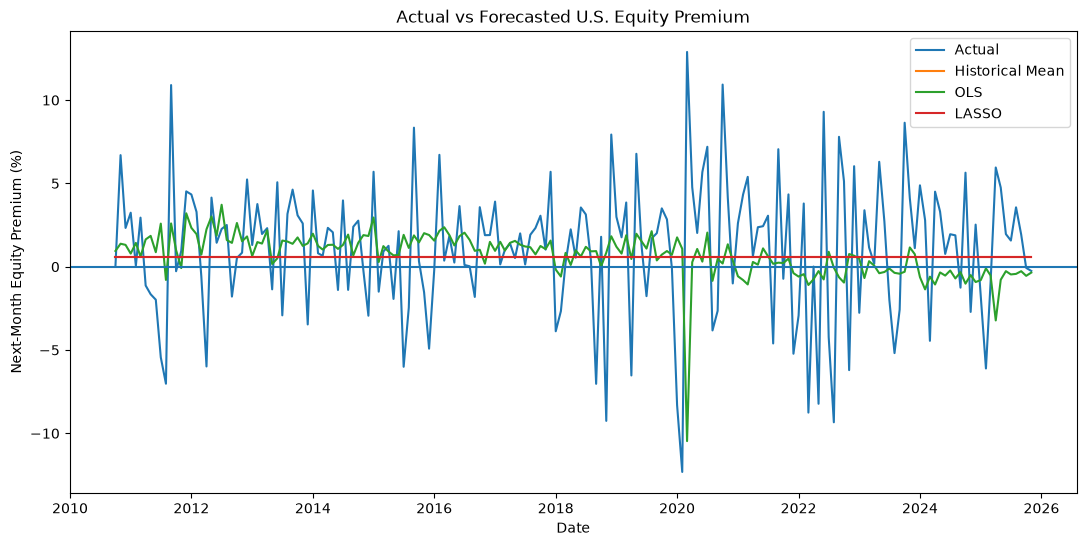

In [42]:
plt.figure(figsize=(13, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual"
)

plt.plot(
    y_test.index,
    historical_mean_pred,
    label="Historical Mean"
)

plt.plot(
    y_test.index,
    ols_pred,
    label="OLS"
)

plt.plot(
    y_test.index,
    lasso_pred,
    label="LASSO"
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Next-Month Equity Premium (%)"
)

plt.title(
    "Actual vs Forecasted U.S. Equity Premium"
)

plt.legend()

plt.show()

**Plot: Selected LASSO Coefficients**

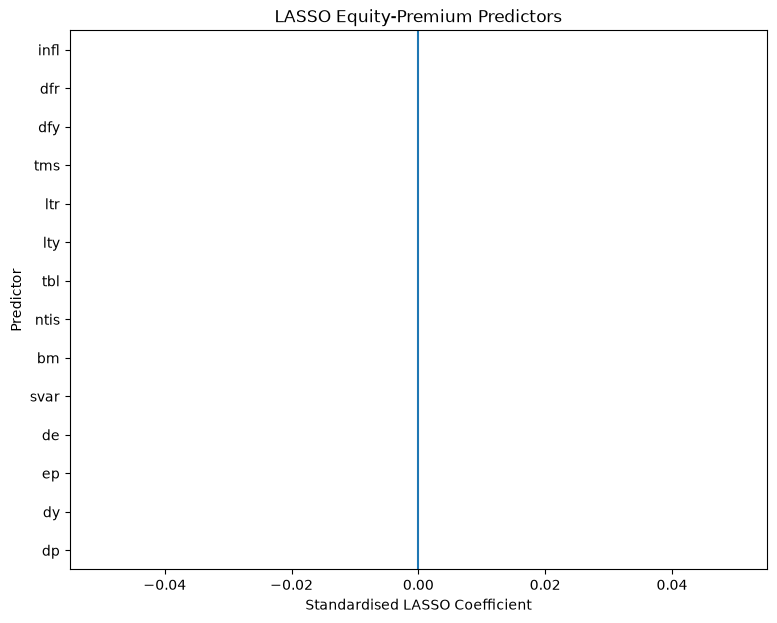

In [43]:
lasso_coefficients.sort_values().plot(
    kind="barh",
    figsize=(9, 7)
)

plt.axvline(
    x=0
)

plt.xlabel(
    "Standardised LASSO Coefficient"
)

plt.ylabel("Predictor")

plt.title(
    "LASSO Equity-Premium Predictors"
)

plt.show()

**Create the LASSO Coefficient Path**

In [44]:
path_scaler = StandardScaler()

X_train_path = (
    path_scaler.fit_transform(
        X_train
    )
)

path_alphas = np.logspace(
    -4,
    1,
    150
)

coefficient_path = []

for alpha in path_alphas:

    model = Lasso(
        alpha=alpha,
        max_iter=100000
    )

    model.fit(
        X_train_path,
        y_train
    )

    coefficient_path.append(
        model.coef_
    )

coefficient_path = np.array(
    coefficient_path
)

**Plot: Coefficient Paths**

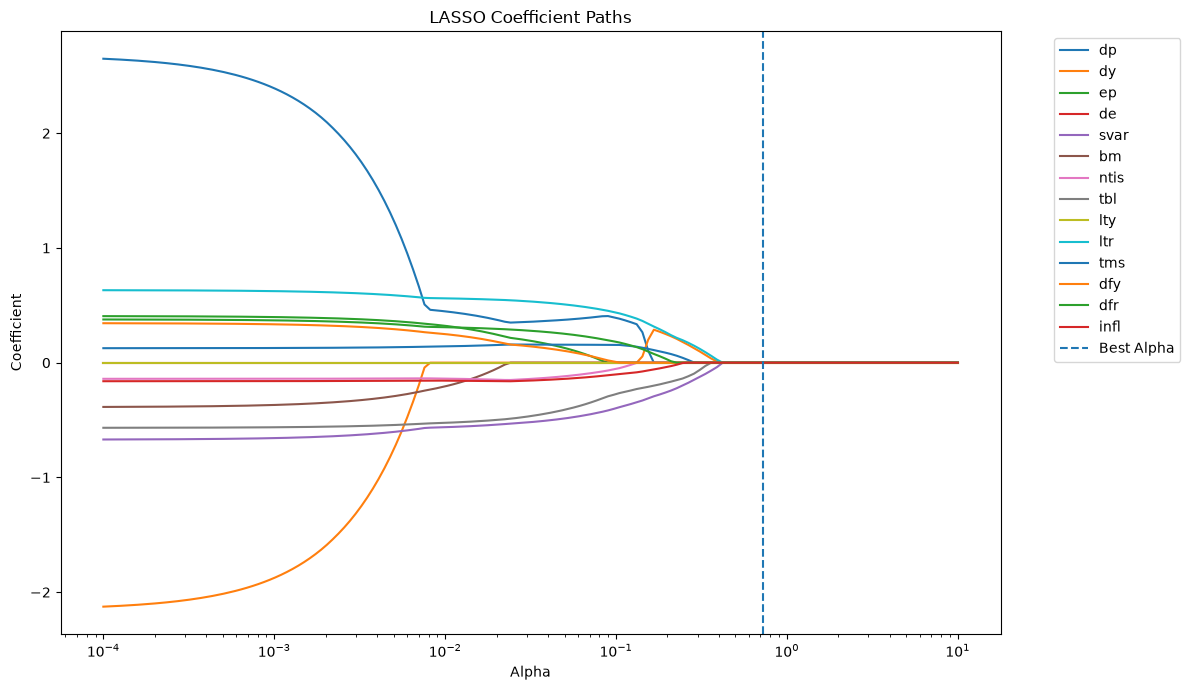

In [45]:
plt.figure(figsize=(12, 7))

for i, feature in enumerate(features):

    plt.semilogx(
        path_alphas,
        coefficient_path[:, i],
        label=feature
    )

plt.axvline(
    best_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")

plt.ylabel("Coefficient")

plt.title(
    "LASSO Coefficient Paths"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

**Plot: Cross-Validation Error Against Alpha**

In [46]:
cv_results = pd.DataFrame(
    lasso_search.cv_results_
)

cv_results["RMSE"] = (
    -cv_results["mean_test_score"]
)

cv_results["alpha"] = (
    cv_results[
        "param_lasso__alpha"
    ].astype(float)
)

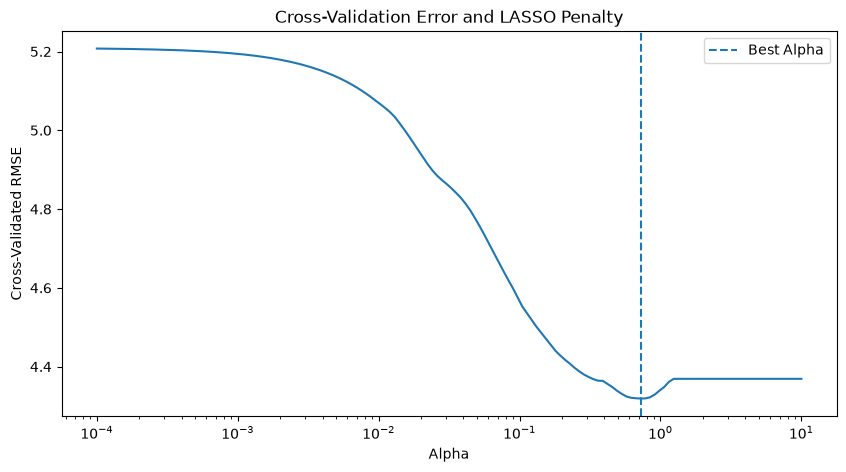

In [47]:
plt.figure(figsize=(10, 5))

plt.semilogx(
    cv_results["alpha"],
    cv_results["RMSE"]
)

plt.axvline(
    best_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel("Alpha")

plt.ylabel(
    "Cross-Validated RMSE"
)

plt.title(
    "Cross-Validation Error and LASSO Penalty"
)

plt.legend()

plt.show()

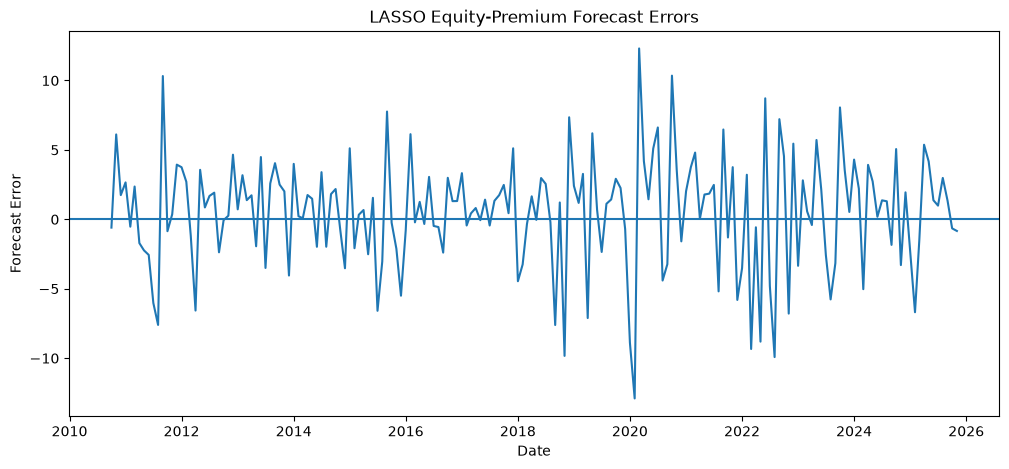

In [48]:
lasso_residuals = (
    y_test.values
    - lasso_pred
)

plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    lasso_residuals
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel("Forecast Error")

plt.title(
    "LASSO Equity-Premium Forecast Errors"
)

plt.show()

**Cumulative Forecast Performance Against the Historical Mean**

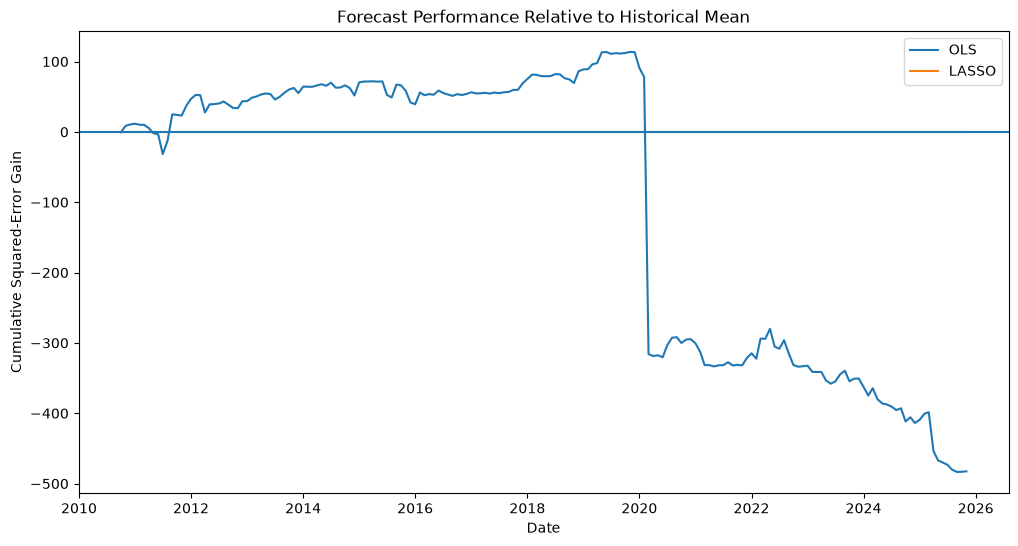

In [49]:
benchmark_squared_error = (
    y_test.values
    - historical_mean_pred
) ** 2

ols_squared_error = (
    y_test.values
    - ols_pred
) ** 2

lasso_squared_error = (
    y_test.values
    - lasso_pred
) ** 2

ols_cumulative_gain = np.cumsum(
    benchmark_squared_error
    - ols_squared_error
)

lasso_cumulative_gain = np.cumsum(
    benchmark_squared_error
    - lasso_squared_error
)

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    ols_cumulative_gain,
    label="OLS"
)

plt.plot(
    y_test.index,
    lasso_cumulative_gain,
    label="LASSO"
)

plt.axhline(
    y=0
)

plt.xlabel("Date")

plt.ylabel(
    "Cumulative Squared-Error Gain"
)

plt.title(
    "Forecast Performance Relative to Historical Mean"
)

plt.legend()

plt.show()

In [50]:
forecast_results = pd.DataFrame({
    "Actual": y_test,
    "Historical_Mean":
        historical_mean_pred,
    "OLS": ols_pred,
    "LASSO": lasso_pred
})

forecast_results.head(10).round(3)

,Actual,Historical_Mean,OLS,LASSO
DATE,,,,
2010-10-01,-0.015,0.581,0.944,0.581
2010-11-01,6.696,0.581,1.378,0.581
2010-12-01,2.325,0.581,1.309,0.581
2011-01-01,3.241,0.581,0.785,0.581
2011-02-01,0.052,0.581,1.428,0.581
2011-03-01,2.944,0.581,0.605,0.581
2011-04-01,-1.131,0.581,1.636,0.581
2011-05-01,-1.654,0.581,1.850,0.581
2011-06-01,-1.983,0.581,0.869,0.581


In [51]:
forecast_results.tail(10).round(3)

,Actual,Historical_Mean,OLS,LASSO
DATE,,,,
2025-02-01,-6.110,0.581,-0.100,0.581
2025-03-01,-0.932,0.581,-0.529,0.581
2025-04-01,5.953,0.581,-3.225,0.581
2025-05-01,4.751,0.581,-0.785,0.581
2025-06-01,1.956,0.581,-0.269,0.581
2025-07-01,1.568,0.581,-0.465,0.581
2025-08-01,3.564,0.581,-0.433,0.581
2025-09-01,1.931,0.581,-0.271,0.581
2025-10-01,-0.071,0.581,-0.549,0.581


In [52]:
performance.to_csv(
    "problem_12_model_performance.csv",
    index=False
)

coefficient_table.to_csv(
    "problem_12_coefficients.csv"
)

forecast_results.to_csv(
    "problem_12_forecasts.csv"
)

cv_results.to_csv(
    "problem_12_lasso_cv_results.csv",
    index=False
)

## END